In [119]:
from tabnanny import verbose
from tkinter import Grid
from unittest.mock import inplace

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path

from sentence_transformers import SentenceTransformer

import spacy

from tm.Mobile_App_Reviews_Classification_Word_Embeddings import param_grid

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [120]:
Path.cwd()

WindowsPath('C:/Users/Tea/PycharmProjects/nap-text-mining-nlp-bert/Primeri zadataka za kolokvijum')

In [121]:
df = pd.read_csv(Path.cwd() / 'data' / 'McDonald_s_Reviews.csv.csv')

In [122]:
df


,reviewer_id,store_address,rating_count,review,rating
0,4187,"724 Broadway, New York, NY 10003, United States",1.670,"They had a very limited space, but to make an ...",4
1,32761,"3501 Biscayne Blvd, Miami, FL 33137, United St...",2.810,clean restaurant customer service very good,5
2,12196,"1044 US-11, Champlain, NY 12919, United States",1.306,Fast and friendly service. Nice location.,5
3,12502,"501 W Imperial Hwy, Los Angeles, CA 90044, Uni...",2.722,Everytime I order from here something is alway...,1
4,3165,"429 7th Ave, New York, NY 10001, United States",2.052,Very fast and helpful oops and respectful,5
...,...,...,...,...,...
4995,2773,"72-69 Kissena Blvd, Queens, NY 11367, United S...",2.193,Dollar menu.,5
4996,2446,"72-69 Kissena Blvd, Queens, NY 11367, United S...",2.193,This place is great for kids to play when the ...,5
4997,28272,"5725 W Irlo Bronson Memorial Hwy, Kissimmee, F...",5.567,"Having kiosks, instead of human cashier, reall...",2
4998,8048,"11382 US-441, Orlando, FL 32837, United States",1.861,The Big Mac was good may just the way I ordere...,5


In [123]:
def sredisentiment(rating):
    if rating == 3:
        return 'neutral'
    if rating <3:
        return 'negativan'
    return 'pozitivan'

In [124]:
df['sentiment']=df.rating.apply(sredisentiment)

In [125]:
df.isna().sum()

reviewer_id      0
store_address    0
rating_count     0
review           3
rating           0
sentiment        0
dtype: int64

In [126]:
df=df.dropna()

In [127]:
df.info()

<class 'pandas.DataFrame'>
Index: 4997 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    4997 non-null   int64  
 1   store_address  4997 non-null   str    
 2   rating_count   4997 non-null   float64
 3   review         4997 non-null   str    
 4   rating         4997 non-null   int64  
 5   sentiment      4997 non-null   str    
dtypes: float64(1), int64(2), str(3)
memory usage: 273.3 KB


In [128]:
df.sentiment.value_counts()

sentiment
pozitivan    2390
negativan    1851
neutral       756
Name: count, dtype: int64

In [129]:
nlp_pipe=spacy.load('en_core_web_sm')

In [130]:
#fja sredi tekst
#pa tfidf ili countvectorizer za bow ili samo
def srediTekst(doc):
    ocisceniTokeni=[]
    tokens=nlp_pipe(doc)

    for token in tokens:
        lemma_lower=token.lemma_.lower()
        if token.is_punct or token.is_space or token.like_url or token.like_email or token.like_num or not token.is_alpha or len(lemma_lower) < 2:
            continue
        if token.is_stop and lemma_lower not in {"not", "no", "never"}:
            continue
        ocisceniTokeni.append(lemma_lower)
    return ocisceniTokeni

In [131]:
vectorizer=TfidfVectorizer(token_pattern=None,tokenizer=srediTekst,max_df=0.99,min_df=0.00)

In [132]:
df.info()

<class 'pandas.DataFrame'>
Index: 4997 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    4997 non-null   int64  
 1   store_address  4997 non-null   str    
 2   rating_count   4997 non-null   float64
 3   review         4997 non-null   str    
 4   rating         4997 non-null   int64  
 5   sentiment      4997 non-null   str    
dtypes: float64(1), int64(2), str(3)
memory usage: 273.3 KB


In [133]:
df.store_address.value_counts()

store_address
9814 International Dr, Orlando, FL 32819, United States                       264
10901 Riverside Dr, North Hollywood, CA 91602, United States                  255
3501 Biscayne Blvd, Miami, FL 33137, United States                            254
1415 E State Rd, Fern Park, FL 32730, United States                           247
5725 W Irlo Bronson Memorial Hwy, Kissimmee, FL 34746, United States          242
632 S R L Thornton Freeway Service Rd, Dallas, TX 75203, United States        213
621 Broadway, Newark, NJ 07104, United States                                 203
72-69 Kissena Blvd, Queens, NY 11367, United States                           198
1698 US-209, Brodheadsville, PA 18322, United States                          177
1100 N US Hwy 377, Roanoke, TX 76262, United States                           173
724 Broadway, New York, NY 10003, United States                               172
By Mandalay Bay, 3999 S Las Vegas Blvd, Las Vegas, NV 89119, United States    169
42

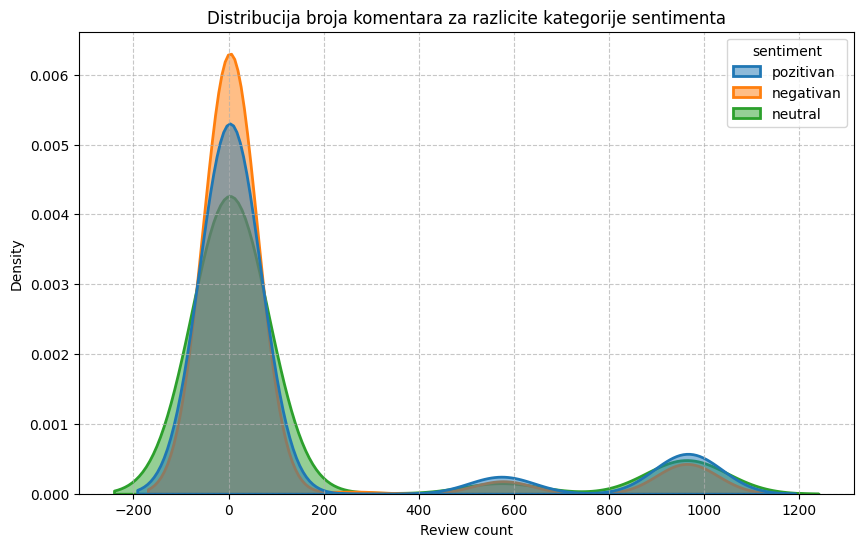

In [134]:
plt.figure(figsize=(10, 6))

sb.kdeplot(data=df,
           x='rating_count',
           hue='sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija broja komentara za razlicite kategorije sentimenta')
plt.xlabel('Review count')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [135]:
#vidimo da su raspodele skoro identicne , samim tim nemoramo da ukljucimo ovu varijablu .

In [136]:
df.info()

<class 'pandas.DataFrame'>
Index: 4997 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    4997 non-null   int64  
 1   store_address  4997 non-null   str    
 2   rating_count   4997 non-null   float64
 3   review         4997 non-null   str    
 4   rating         4997 non-null   int64  
 5   sentiment      4997 non-null   str    
dtypes: float64(1), int64(2), str(3)
memory usage: 273.3 KB


In [137]:
#treba ukljuciti ocigledno samo review.
pipe=Pipeline(
    [
        ('vectorizer',vectorizer),
        ('classifier',LogisticRegression(random_state=42,max_iter=2000))

    ]
)

In [138]:
y_encode,y_labels=pd.factorize(df.sentiment)

In [139]:
X_train, X_test, y_train, y_test = train_test_split(df.review, y_encode, test_size=0.2, random_state=42,stratify=y_encode)

In [141]:
model=pipe.fit(X_train,y_train)

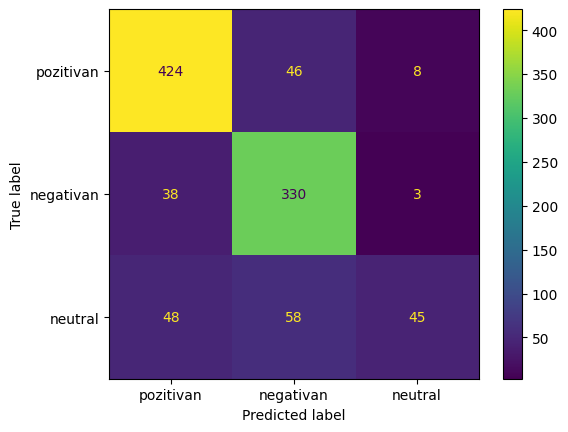

In [151]:
y_pred = model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,display_labels=y_labels)

In [146]:
y_labels

Index(['pozitivan', 'negativan', 'neutral'], dtype='str')

In [150]:
print(classification_report(y_test,y_pred,target_names=y_labels))

              precision    recall  f1-score   support

   pozitivan       0.83      0.89      0.86       478
   negativan       0.76      0.89      0.82       371
     neutral       0.80      0.30      0.43       151

    accuracy                           0.80      1000
   macro avg       0.80      0.69      0.70      1000
weighted avg       0.80      0.80      0.78      1000



Mozemo da vidimo da:

Da je makro average koji gleda sve klase podjednako na precisionu 80% na recallu 69% a kada gledamo weightet koji vise uvazava klasu sa vise obzervacija 80% i za precisiion i recall ..

#macro average je 0.70 i manji je neko weighted zbog toga sto je nebalansiran data set jer imamo previse pozitivnih obzervacija u odnosu na ostale 2 .

Vidimo da model dosta slabo predvidja neutralno samo 30% reccala , gde je  recall definisan kao broj tacno pogodjenih od svih poztiivnih obzervacija te klase.



In [144]:
#mozemo

Help on function classification_report in module sklearn.metrics._classification:

classification_report(
    y_true,
    y_pred,
    *,
    labels=None,
    target_names=None,
    sample_weight=None,
    digits=2,
    output_dict=False,
    zero_division='warn'
)
    Build a text report showing the main classification metrics.

    Read more in the :ref:`User Guide <classification_report>`.

    Parameters
    ----------
    y_true : 1d array-like, or label indicator array / sparse matrix
        Ground truth (correct) target values. Sparse matrix is only supported when
        targets are of :term:`multilabel` type.

    y_pred : 1d array-like, or label indicator array / sparse matrix
        Estimated targets as returned by a classifier. Sparse matrix is only
        supported when targets are of :term:`multilabel` type.

    labels : array-like of shape (n_labels,), default=None
        Optional list of label indices to include in the report.

    target_names : array-like of shape

In [153]:
#podesavanje hiperparematara  da imam vise vremena
#TfidfVectorizer:
        #ngram_range=[(1, 1),(1, 2),(1,3)]
        #max_df=1.0, [0.95,0.96,0.978,0.98,0.99]
        #min_df=1, [0.01,0.02,0.03,0.04]

# ovo ne znam dal treba        sublinear_tf=False,
#Logisitci bi namestao
   #  C=[0.1,1,10,100,1000]


# u grid searchu isprobao f1 scoring sa cv sto vecim i mozda StratifiedKfoldom

In [156]:
param_gridd={
    'vectorizer__ngram_range':[(1,1),(1,2)],
    'classifier__C':[0.01,1,100]
}

In [162]:
cv=GridSearchCV(pipe,param_grid=param_gridd,scoring='f1_macro',cv=5,verbose=2)


In [163]:
grid_search=cv.fit(X_train,y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 1); total time=  14.2s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 1); total time=  14.2s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 1); total time=  14.6s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 1); total time=  14.6s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 1); total time=  15.3s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 2); total time=  15.3s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 2); total time=  15.6s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 2); total time=  15.4s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 2); total time=  16.0s
[CV] END .classifier__C=0.01, vectorizer__ngram_range=(1, 2); total time=  15.9s
[CV] END ....classifier__C=1, vectorizer__ngram_range=(1, 1); total time=  15.4s
[CV] END ....classifier__C=1, vectorizer__ngram_r

C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[CV] END ..classifier__C=100, vectorizer__ngram_range=(1, 1); total time=  16.0s


C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[CV] END ..classifier__C=100, vectorizer__ngram_range=(1, 1); total time=  16.2s
[CV] END ..classifier__C=100, vectorizer__ngram_range=(1, 1); total time=  16.2s


C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


... (4 outputs left out)

[CV] END ..classifier__C=100, vectorizer__ngram_range=(1, 2); total time=  16.3s
[CV] END ..classifier__C=100, vectorizer__ngram_range=(1, 2); total time=  15.2s
[CV] END ..classifier__C=100, vectorizer__ngram_range=(1, 2); total time=  14.9s


C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[CV] END ..classifier__C=100, vectorizer__ngram_range=(1, 2); total time=  15.1s


C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [181]:
def get_model_metrics(y_true:np.ndarray, y_pred:np.ndarray, model_name:str):

    # compute P, R, F1 for both averages
    report = classification_report(y_true, y_pred, output_dict=True)

    # compute balanced accuracy
    b_acc = balanced_accuracy_score(y_true, y_pred)

    # extract metrics for the specified averages
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [167]:
cv.best_params_

{'classifier__C': 100, 'vectorizer__ngram_range': (1, 2)}

In [184]:
model2=cv

In [185]:
y_pred_1=y_pred
Y_pred_2=model2.predict(X_test)

In [186]:
pd.DataFrame([get_model_metrics(y_test,Y_pred_2,"Model 2 "),get_model_metrics(y_test,y_pred,"Model 1 ")]).round(2)

,Model,Macro Precision,Macro Recall,Macro F1-Score,Weighted Precision,Weighted Recall,Weighted F1-Score,Balanced Accuracy
0,Model 2,0.75,0.72,0.73,0.79,0.8,0.79,0.72
1,Model 1,0.80,0.69,0.70,0.80,0.8,0.78,0.69


In [ ]:
# vidimo da model 2 ima 0.73 macro f1 score i samim tim bolji je od modela 2 , jer ima bolji recall ali goru macro preciznost .. balanced accuarcy je takodje malo bolji .. .
